In [1]:
from google.colab import files
uploaded = files.upload()

Saving orders.csv to orders.csv


In [2]:
import pandas as pd

orders = pd.read_csv("orders.csv")

print(orders.columns.tolist())
orders.head()

['order_id', 'created_at', 'website_session_id', 'user_id', 'primary_product_id', 'items_purchased', 'price_usd', 'cogs_usd']


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49


In [3]:
orders["created_at"] = pd.to_datetime(orders["created_at"])
orders["price_usd"] = pd.to_numeric(orders["price_usd"], errors="coerce")

valid_orders = orders.dropna(
    subset=["user_id", "order_id", "created_at"]
)

snapshot_date = valid_orders["created_at"].max() + pd.Timedelta(days=1)

rfm = (
    valid_orders.groupby("user_id")
    .agg(
        recency_days=("created_at", lambda dates: (snapshot_date - dates.max()).days),
        frequency=("order_id", "nunique"),
        monetary_usd=("price_usd", "sum")
    )
    .reset_index()
)

rfm.head()


,user_id,recency_days,frequency,monetary_usd
0,13,1058,1,49.99
1,20,1095,1,49.99
2,59,1064,1,49.99
3,104,1095,1,49.99
4,147,1094,1,49.99


In [4]:
customer_count = len(rfm)
repeat_customers = (rfm["frequency"] > 1).sum()
repeat_rate = repeat_customers / customer_count * 100

print("Customers:", customer_count)
print("Repeat customers:", repeat_customers)
print(f"Repeat-customer rate: {repeat_rate:.2f}%")

Customers: 31696
Repeat customers: 591
Repeat-customer rate: 1.86%


In [5]:
import pandas as pd

bins = [0, 0.25, 0.50, 0.75, 1.0]

rfm["R_score"] = pd.cut(
    rfm["recency_days"].rank(method="average", pct=True),
    bins=bins,
    labels=[4, 3, 2, 1],
    include_lowest=True
).astype(int)

rfm["F_score"] = pd.cut(
    rfm["frequency"].rank(method="average", pct=True),
    bins=bins,
    labels=[1, 2, 3, 4],
    include_lowest=True
).astype(int)

rfm["M_score"] = pd.cut(
    rfm["monetary_usd"].rank(method="average", pct=True),
    bins=bins,
    labels=[1, 2, 3, 4],
    include_lowest=True
).astype(int)

rfm["RFM_score"] = rfm[["R_score", "F_score", "M_score"]].astype(str).agg("".join, axis=1)

rfm[["user_id", "recency_days", "frequency", "monetary_usd",
     "R_score", "F_score", "M_score", "RFM_score"]].head()

,user_id,recency_days,frequency,monetary_usd,R_score,F_score,M_score,RFM_score
0,13,1058,1,49.99,1,2,2,122
1,20,1095,1,49.99,1,2,2,122
2,59,1064,1,49.99,1,2,2,122
3,104,1095,1,49.99,1,2,2,122
4,147,1094,1,49.99,1,2,2,122


In [6]:
rfm["frequency"].value_counts().sort_index()


,count
frequency,
1,31105
2,565
3,26


In [7]:
rfm.to_csv("project2_rfm_all_customers.csv", index=False)

from google.colab import files
files.download("project2_rfm_all_customers.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
def label_customer(row):
    if row["frequency"] >= 2 and row["R_score"] >= 3 and row["M_score"] >= 3:
        return "High-value active repeat"
    elif row["frequency"] >= 2 and row["R_score"] >= 3:
        return "Active repeat"
    elif row["frequency"] >= 2:
        return "At-risk repeat"
    elif row["R_score"] >= 3 and row["M_score"] >= 3:
        return "High-value recent one-time"
    elif row["R_score"] >= 3:
        return "Recent one-time"
    else:
        return "Lapsed one-time"

rfm["segment"] = rfm.apply(label_customer, axis=1)

rfm["segment"].value_counts()

,count
segment,
Lapsed one-time,15616
Recent one-time,8244
High-value recent one-time,7245
High-value active repeat,348
At-risk repeat,243


In [9]:
cohort_orders = orders.dropna(
    subset=["user_id", "order_id", "created_at"]
).copy()

cohort_orders["created_at"] = pd.to_datetime(cohort_orders["created_at"])
cohort_orders["order_month"] = (
    cohort_orders["created_at"].dt.to_period("M").dt.to_timestamp()
)

cohort_orders["cohort_month"] = (
    cohort_orders.groupby("user_id")["order_month"].transform("min")
)

cohort_orders["cohort_index"] = (
    (cohort_orders["order_month"].dt.year - cohort_orders["cohort_month"].dt.year) * 12
    + (cohort_orders["order_month"].dt.month - cohort_orders["cohort_month"].dt.month)
)

cohort_counts = (
    cohort_orders.groupby(["cohort_month", "cohort_index"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

cohort_sizes = cohort_counts[0]
retention = (
    cohort_counts.divide(cohort_sizes, axis=0) * 100
).round(1)

retention.head()

cohort_index,0,1,2,3,4
cohort_month,,,,,
2012-03-01,100.0,0.0,0.0,0.0,0.0
2012-04-01,100.0,0.0,0.0,0.0,0.0
2012-05-01,100.0,0.0,0.0,0.0,0.0
2012-06-01,100.0,0.7,0.0,0.0,0.0
2012-07-01,100.0,0.0,0.0,0.0,0.0


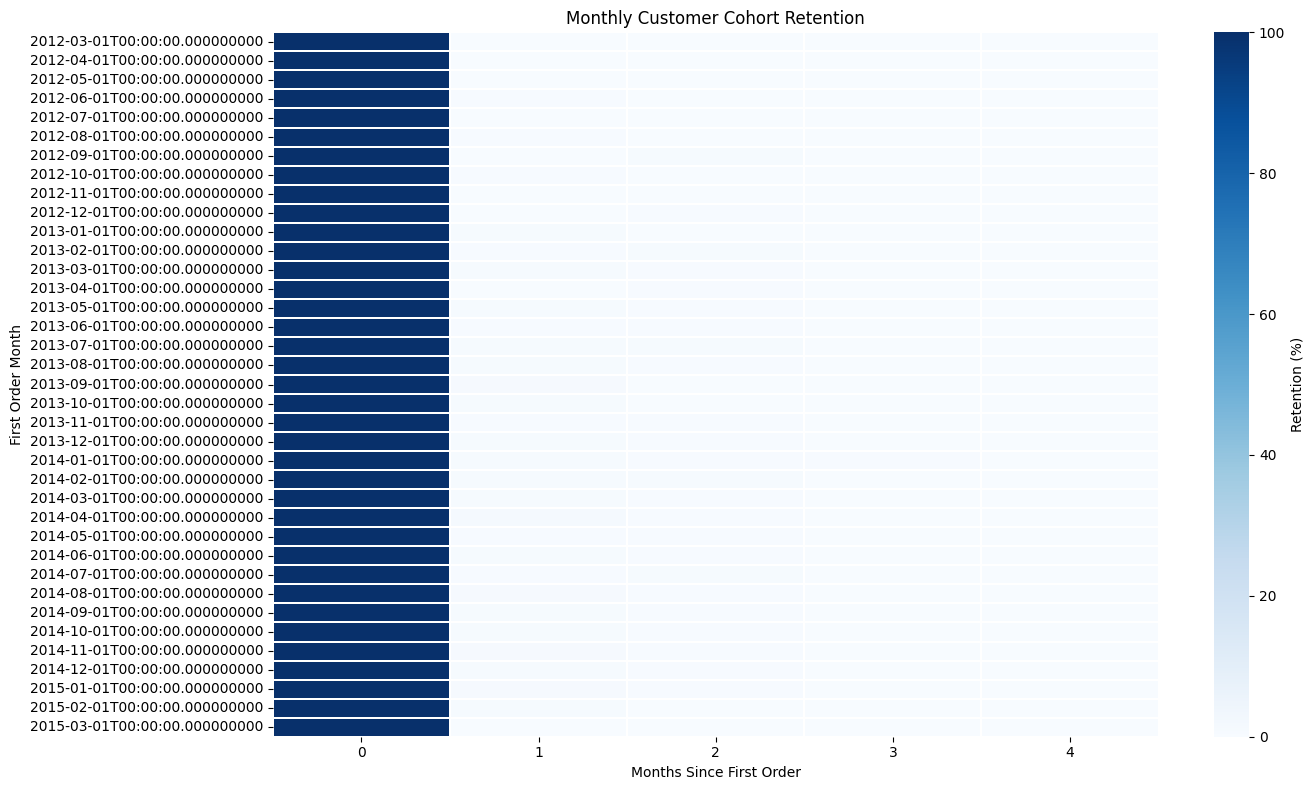

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))
sns.heatmap(
    retention,
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.3,
    cbar_kws={"label": "Retention (%)"}
)

plt.title("Monthly Customer Cohort Retention")
plt.xlabel("Months Since First Order")
plt.ylabel("First Order Month")
plt.tight_layout()
plt.show()

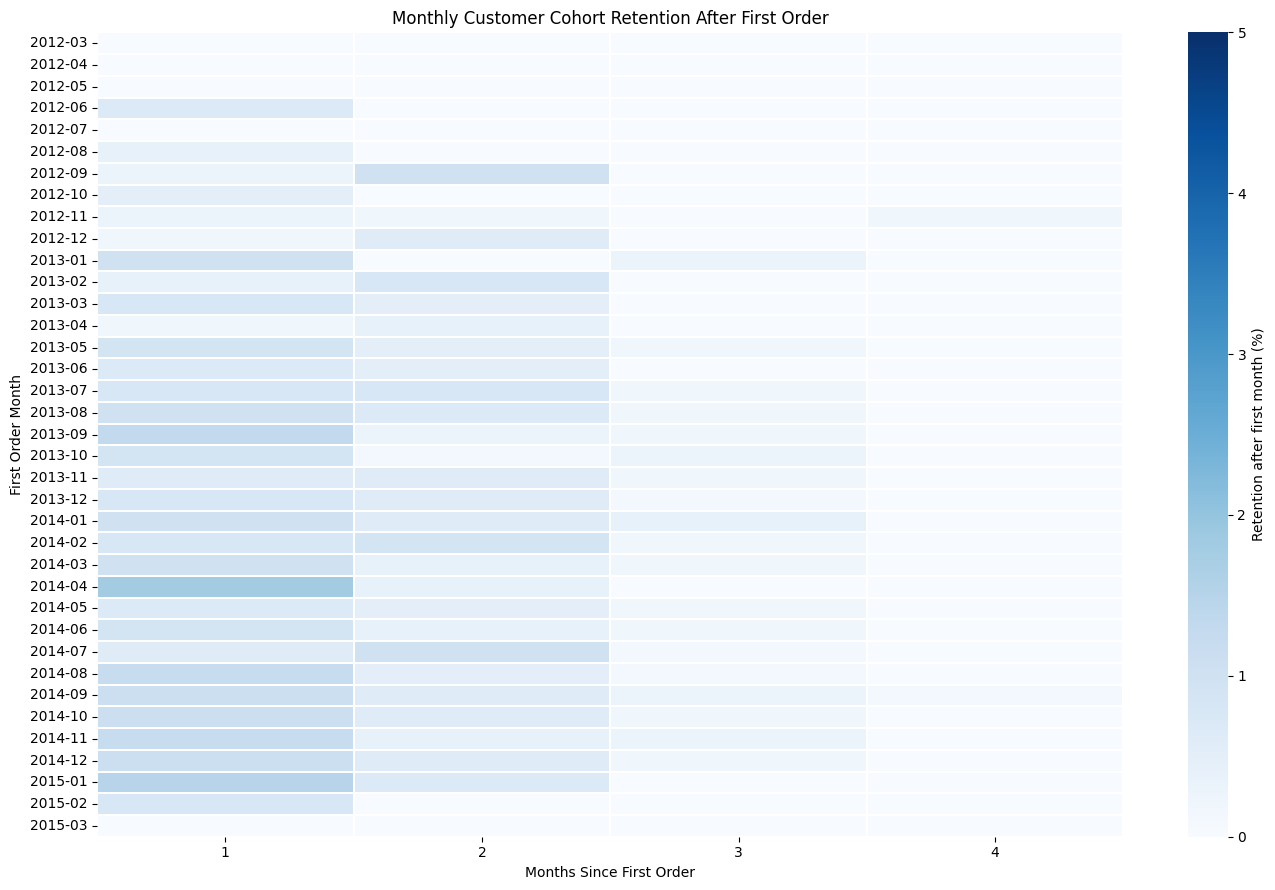

In [11]:
plot_retention = retention.drop(columns=0).copy()
plot_retention.index = pd.to_datetime(plot_retention.index).strftime("%Y-%m")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 9))
sns.heatmap(
    plot_retention,
    cmap="Blues",
    vmin=0,
    vmax=5,
    mask=plot_retention.isna(),
    linewidths=0.3,
    cbar_kws={"label": "Retention after first month (%)"}
)

plt.title("Monthly Customer Cohort Retention After First Order")
plt.xlabel("Months Since First Order")
plt.ylabel("First Order Month")
plt.tight_layout()
plt.show()

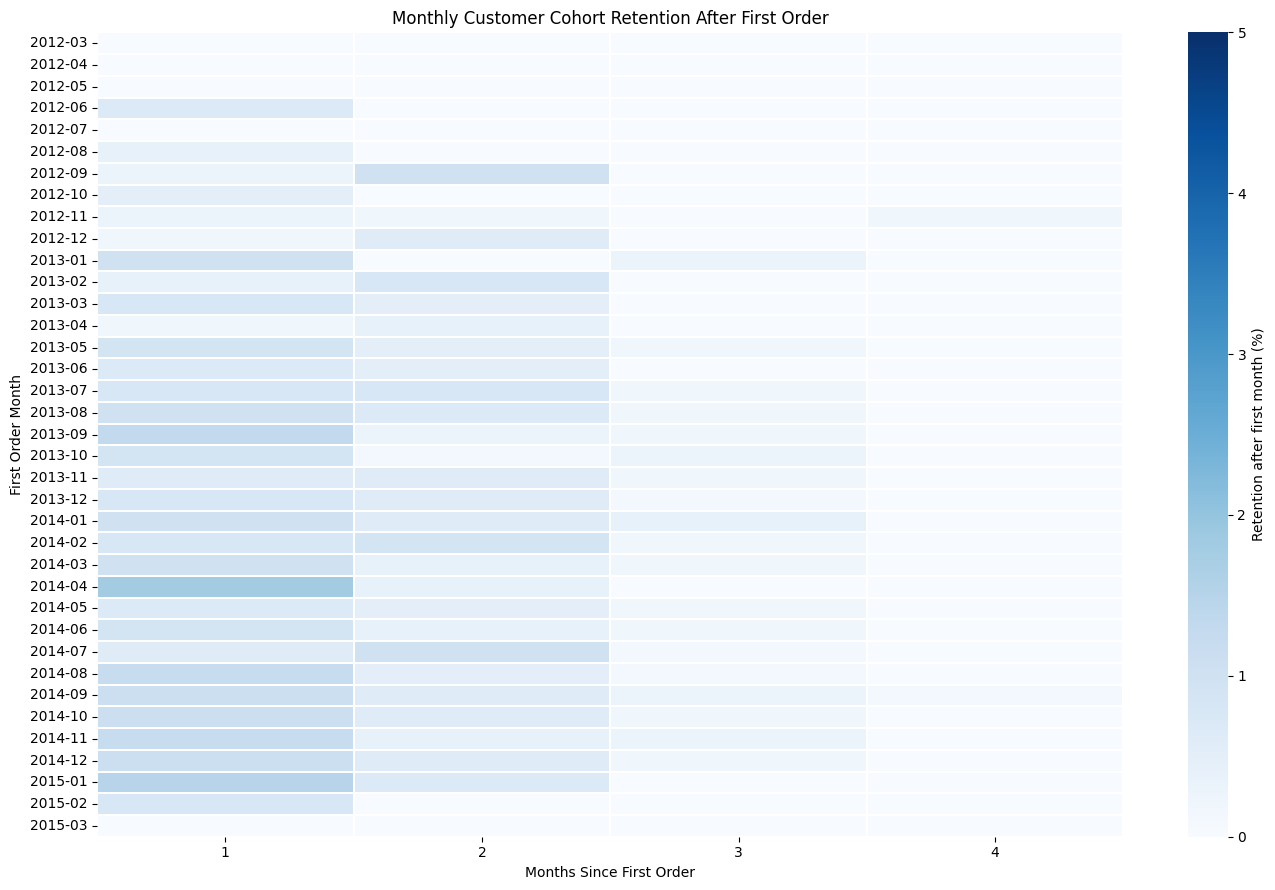

In [12]:
plot_retention = retention.drop(columns=0).copy()
plot_retention.index = pd.to_datetime(plot_retention.index).strftime("%Y-%m")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 9))
sns.heatmap(
    plot_retention,
    cmap="Blues",
    vmin=0,
    vmax=5,
    mask=plot_retention.isna(),
    linewidths=0.3,
    cbar_kws={"label": "Retention after first month (%)"}
)

plt.title("Monthly Customer Cohort Retention After First Order")
plt.xlabel("Months Since First Order")
plt.ylabel("First Order Month")
plt.tight_layout()
plt.show()

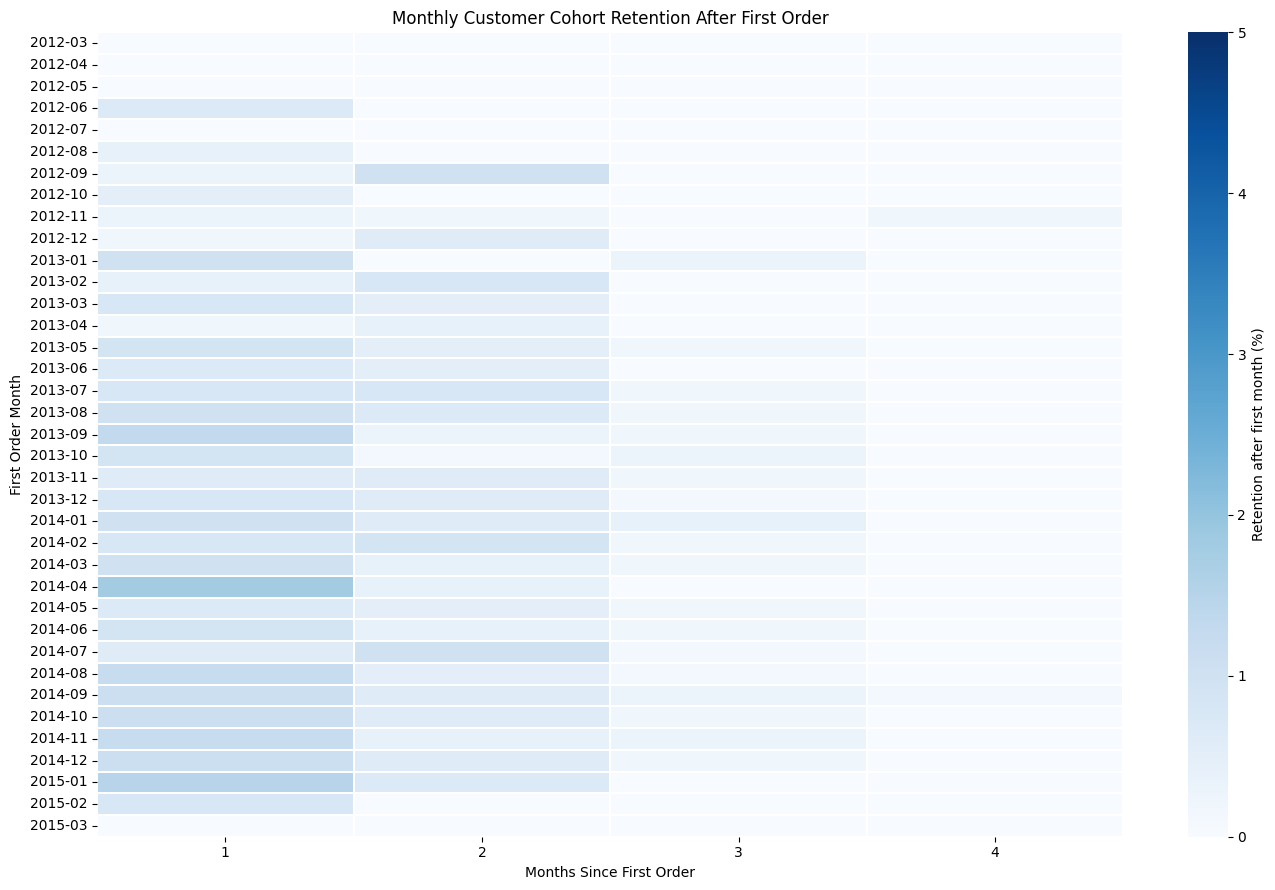

In [13]:
plot_retention = retention.drop(columns=0).copy()
plot_retention.index = pd.to_datetime(plot_retention.index).strftime("%Y-%m")

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 9))
sns.heatmap(
    plot_retention,
    cmap="Blues",
    vmin=0,
    vmax=5,
    mask=plot_retention.isna(),
    linewidths=0.3,
    cbar_kws={"label": "Retention after first month (%)"}
)
plt.title("Monthly Customer Cohort Retention After First Order")
plt.xlabel("Months Since First Order")
plt.ylabel("First Order Month")
plt.tight_layout()
plt.show()

In [14]:
cohort_orders = orders.dropna(
    subset=["user_id", "order_id", "created_at"]
).copy()

cohort_orders["created_at"] = pd.to_datetime(cohort_orders["created_at"])
cohort_orders["order_month"] = (
    cohort_orders["created_at"].dt.to_period("M").dt.to_timestamp()
)

cohort_orders["cohort_month"] = (
    cohort_orders.groupby("user_id")["order_month"].transform("min")
)

cohort_orders["cohort_index"] = (
    (cohort_orders["order_month"].dt.year - cohort_orders["cohort_month"].dt.year) * 12
    + (cohort_orders["order_month"].dt.month - cohort_orders["cohort_month"].dt.month)
)

cohort_counts = (
    cohort_orders.groupby(["cohort_month", "cohort_index"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

cohort_sizes = cohort_counts[0]
retention = (
    cohort_counts.divide(cohort_sizes, axis=0) * 100
).round(1)

display(retention.head())

cohort_index,0,1,2,3,4
cohort_month,,,,,
2012-03-01,100.0,0.0,0.0,0.0,0.0
2012-04-01,100.0,0.0,0.0,0.0,0.0
2012-05-01,100.0,0.0,0.0,0.0,0.0
2012-06-01,100.0,0.7,0.0,0.0,0.0
2012-07-01,100.0,0.0,0.0,0.0,0.0


In [15]:
rfm["segment"].value_counts()

,count
segment,
Lapsed one-time,15616
Recent one-time,8244
High-value recent one-time,7245
High-value active repeat,348
At-risk repeat,243


In [16]:
import pandas as pd

orders["created_at"] = pd.to_datetime(orders["created_at"])

orders["order_month"] = orders["created_at"].dt.to_period("M")
orders["cohort_month"] = orders.groupby("user_id")["order_month"].transform("min")

orders["cohort_index"] = (
    (orders["order_month"].dt.year - orders["cohort_month"].dt.year) * 12
    + orders["order_month"].dt.month
    - orders["cohort_month"].dt.month
)

cohort_counts = (
    orders.groupby(["cohort_month", "cohort_index"])["user_id"]
    .nunique()
    .unstack()
)

cohort_sizes = cohort_counts[0]
retention = cohort_counts.div(cohort_sizes, axis=0) * 100

# Leave months blank when they are beyond the end of the dataset
last_month = orders["order_month"].max()

for cohort_month in retention.index:
    last_observed_index = (
        (last_month.year - cohort_month.year) * 12
        + last_month.month
        - cohort_month.month
    )
    retention.loc[
        cohort_month, retention.columns > last_observed_index
    ] = float("nan")

retention.index = retention.index.astype(str)
retention.round(1)

cohort_index,0,1,2,3,4
cohort_month,,,,,
2012-03,100.0,NaN,NaN,NaN,NaN
2012-04,100.0,NaN,NaN,NaN,NaN
2012-05,100.0,NaN,NaN,NaN,NaN
2012-06,100.0,0.7,NaN,NaN,NaN
2012-07,100.0,NaN,NaN,NaN,NaN
2012-08,100.0,0.4,NaN,NaN,NaN
2012-09,100.0,0.3,1.0,NaN,NaN
2012-10,100.0,0.5,NaN,NaN,NaN
2012-11,100.0,0.3,0.2,NaN,0.2


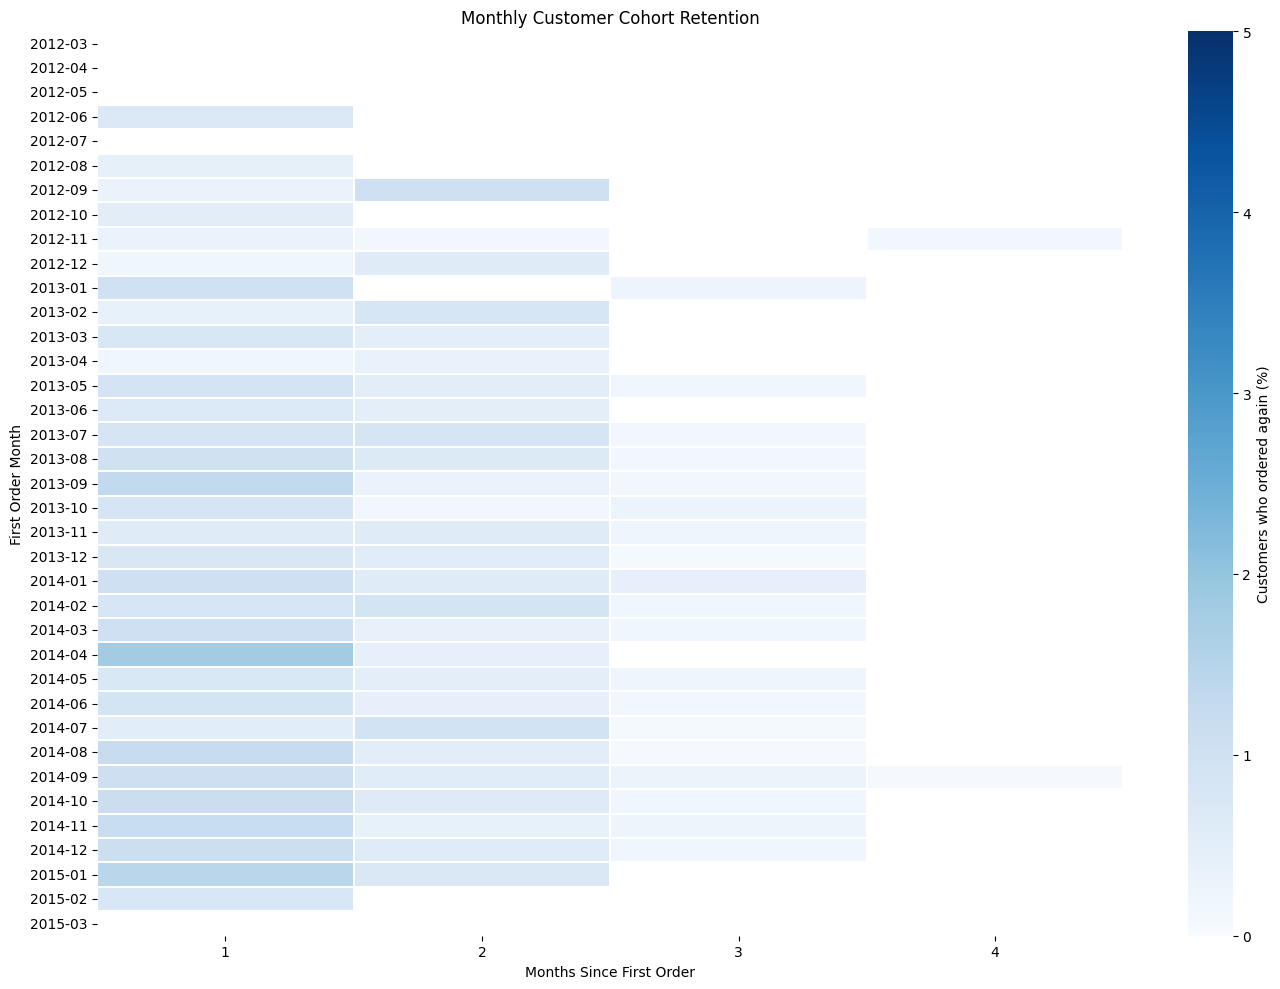

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_retention = retention.drop(columns=0, errors="ignore")

plt.figure(figsize=(14, 10))
sns.heatmap(
    plot_retention,
    cmap="Blues",
    vmin=0,
    vmax=5,
    mask=plot_retention.isna(),
    linewidths=0.2,
    cbar_kws={"label": "Customers who ordered again (%)"}
)
plt.title("Monthly Customer Cohort Retention")
plt.xlabel("Months Since First Order")
plt.ylabel("First Order Month")
plt.tight_layout()
plt.show()

In [18]:
month_one_retention = retention[1].dropna()

print("Cohorts with a full month of follow-up:", len(month_one_retention))
print(f"Average month-one retention: {month_one_retention.mean():.2f}%")
print(f"Highest month-one retention: {month_one_retention.max():.2f}%")
print(f"Lowest month-one retention: {month_one_retention.min():.2f}%")

month_one_retention.round(2)

Cohorts with a full month of follow-up: 32
Average month-one retention: 0.84%
Highest month-one retention: 1.81%
Lowest month-one retention: 0.18%


,1
cohort_month,
2012-06,0.72
2012-08,0.44
2012-09,0.35
2012-10,0.54
2012-11,0.33
2012-12,0.20
2013-01,1.03
2013-02,0.41
2013-03,0.79


In [19]:
from google.colab import files

retention.to_csv("cohort_retention.csv")
files.download("cohort_retention.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from google.colab import files

rfm.to_csv("project2_rfm_customers.csv", index=False)
files.download("project2_rfm_customers.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>